In [15]:
import torch
import numpy as np
from torch.utils import data
from d2l import torch as d2l

true_w = torch.tensor([2,-3.4])
true_b = 4.2
features,labels = d2l.synthetic_data(true_w,true_b,1000)

In [16]:
print('features:',features[0],'\n','labels:',labels[0])

features: tensor([ 0.8955, -0.1781]) 
 labels: tensor([6.5997])


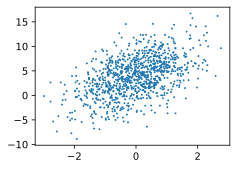

In [17]:
#w在w1维度与y的可视化图
d2l.set_figsize()
d2l.plt.scatter(features[:,0].detach().numpy(),
    labels.detach().numpy(),1)

In [18]:
def load_array(data_arrays,batch_size,is_train = True):
    dataset = data.TensorDataset(*data_arrays)
    return data.DataLoader(dataset,batch_size,shuffle=is_train)

batch_size = 10
data_iter = load_array((features,labels),batch_size)

In [6]:
next(iter(data_iter))

[tensor([[-0.2117,  0.3858],
         [ 0.1909,  0.2948],
         [-0.5268,  0.8695],
         [ 0.8976,  0.7386],
         [-1.8339, -0.4470],
         [ 0.9805,  1.4289],
         [ 0.0675, -0.2583],
         [-1.6250,  0.0928],
         [-1.6513,  1.8065],
         [-2.7609,  1.3980]]),
 tensor([[ 2.4603],
         [ 3.5722],
         [ 0.1879],
         [ 3.4903],
         [ 2.0534],
         [ 1.3135],
         [ 5.2170],
         [ 0.6333],
         [-5.2522],
         [-6.0776]])]

In [7]:
from torch import nn

net = nn.Sequential(nn.Linear(2,1))

In [8]:
net[0].weight.data.normal_(0,0.01)
net[0].bias.data.fill_(0)

tensor([0.])

* Mean Square Error Loss

In [9]:
loss = nn.MSELoss()

In [10]:
trainer = torch.optim.SGD(net.parameters(),lr = 0.03)

In [11]:
num_epochs = 3
for epoch in range(num_epochs):
    for x,y in data_iter:
        l = loss(net(x),y)
        trainer.zero_grad()
        l.backward()
        trainer.step()
    l = loss(net(features),labels)
    print(f'epoch{epoch+1},loss{l:f}')

epoch1,loss0.000289
epoch2,loss0.000107
epoch3,loss0.000109


In [12]:
w = net[0].weight.data
print('w的估计误差：', true_w - w.reshape(true_w.shape))
b = net[0].bias.data
print('b的估计误差：', true_b - b)

w的估计误差： tensor([0.0007, 0.0002])
b的估计误差： tensor([0.0009])


In [13]:
import numpy as np
import torch 
from d2l import torch as d2l
from torch.utils import data


In [132]:
true_w = torch.tensor([2.0,-3.4])
true_b = 4.0
features,labels = d2l.synthetic_data(true_w,true_b,1000)

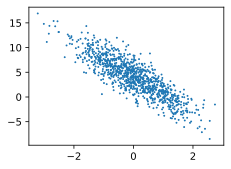

In [133]:
d2l.set_figsize()
d2l.plt.scatter(features[:,1].detach().numpy(),
                labels.detach().numpy(),1)

In [134]:
def load_array(data_arrays,batch_size,is_train = True):
    dataset = data.TensorDataset(*data_arrays)
    return data.DataLoader(dataset,batch_size,shuffle = is_train)

In [135]:
batch_size = 10
data_iter = load_array((features,labels),batch_size)

In [136]:
next(iter(data_iter))

[tensor([[-0.8423,  0.4596],
         [-0.0908, -1.8486],
         [ 0.0390, -0.0118],
         [ 0.0151,  0.9574],
         [ 0.6704,  0.8999],
         [-0.6074,  0.5672],
         [ 0.0304,  1.0737],
         [ 2.1382, -0.1206],
         [ 0.2538,  0.3608],
         [-0.9710,  0.3232]]),
 tensor([[ 0.7593],
         [10.0967],
         [ 4.1274],
         [ 0.7621],
         [ 2.2508],
         [ 0.8514],
         [ 0.4153],
         [ 8.6723],
         [ 3.2757],
         [ 0.9613]])]

In [137]:
from torch import nn
net = nn.Sequential(nn.Linear(2,1))

In [138]:
net[0].weight.data.normal_(0,0.001)
net[0].bias.data.fill_(0)

tensor([0.])

In [139]:
loss = nn.MSELoss()

In [140]:
trainer = torch.optim.SGD(net.parameters(),lr = 0.03)

In [141]:
num_epochs = 3
for epoch in range(num_epochs):
    for x,y in data_iter:
        l = loss(net(x),y)
        trainer.zero_grad()
        l.backward()
        trainer.step()
    l = loss(net(features),labels)
    print(f'epoch{epoch+1},loss{l:f}')

epoch1,loss0.000243
epoch2,loss0.000105
epoch3,loss0.000105


In [143]:
w = net[0].weight.data
print('w的估计误差：', true_w - w.reshape(true_w.shape))
b = net[0].bias.data
print('b的估计误差：', true_b - b)

w的估计误差： tensor([ 2.0020, -3.4105])
b的估计误差： tensor([4.])
